# Exploration du dataset MNIST

Ce notebook a pour objectif d'explorer le jeu de données MNIST avant toute phase de omdélisation.

Objectifs :

*   Charger le dataset ;
*   Vérifier sa structure ;
*   Visualiser plusieurs exemples ;
*   Étudier la répartition des classes ;
*   Préparer les données pour les modèles de Machine Learning et Deep Learning.

# Configuration de l'environnement

Afin de garantir la reproductibilité des expériences, une graine aléatoire fixe est utilisée.

In [44]:
SEED = 42

In [45]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.datasets import mnist

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seed fixée :", SEED)

Seed fixée : 42


# Chargement du dataset MNIST

Le dataset est chargé depuis Tensorflow/Keras.

La base MNIST contient : 

*   60 000 images d'entraînement ;
*   10 000 images de test ;
*   des images de taille 28 x 28 pixels ;
*   10 classes correspondant aux chiffres de 0 à 9.

In [46]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

# Vérification de la structure des données

Nous vérifions les dimensions des ensembles d'entraînement et de test

In [47]:
print("Train :", x_train_full.shape)
print("Labels train :", y_train_full.shape)

print("Test :", x_test.shape)
print("Labels test :", y_test.shape)

Train : (60000, 28, 28)
Labels train : (60000,)
Test : (10000, 28, 28)
Labels test : (10000,)


# Vérification des classes présentes

L'objectif est de s'assurer que les dix chiffres sont bien représentés dans le dataset. 

In [48]:
print("Classes présentes :", np.unique(y_train_full))

Classes présentes : [0 1 2 3 4 5 6 7 8 9]


# Conclusion intermédiaire

Le chargement du dataset s'est effectué correctement.

Observations :

- 60 000 images d'entraînement ;
- 10 000 images de test ;
- dimensions conformes (28 × 28) ;
- présence des 10 classes attendues.

Le dataset est prêt pour l'étape suivante : la visualisation et l'analyse exploratoire des images.

# Vérification du nombre d'exemples

Nous vérifions le nombre d'images présentes dans cahque ensemble afin de confirmer la conformité du dataset avec sa documentation.

In [49]:
print(f"Nombre d'images d'entraînement : {len(x_train_full)}")
print(f"Nombre de labels d'entraînement : {len(y_train_full)}")

print(f"Nombre d'images de test : {len(x_test)}")
print(f"Nombre de labels de test : {len(y_test)}")

Nombre d'images d'entraînement : 60000
Nombre de labels d'entraînement : 60000
Nombre d'images de test : 10000
Nombre de labels de test : 10000


# Vérification des labels

Nous vérifions que les labels associés aux images correspondent bien aux chiffres attendus.

In [50]:
print("Premiers labels d'entraînement :")
print(y_train_full[:20])

print("Classe minimale :", y_train_full.min())
print("Classe maximale :", y_train_full.max())

Premiers labels d'entraînement :
[5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]
Classe minimale : 0
Classe maximale : 9


# Conclusion DATA-01

Le dataset MNIST a été chargé avec succès.

Vérifications réalisées :

- 60 000 images d'entraînement ;
- 10 000 images de test ;
- dimensions des images : 28 × 28 pixels ;
- présence des 10 classes (0 à 9) ;
- cohérence entre les images et leurs labels.

Le dataset est conforme à la documentation officielle et prêt pour l'analyse exploratoire.

# Visualisation des classes

Afin de mieux comprendre le contenu du dataset, nous affichons un exemple représentatif de cahcun des dix calsses présetnes dans MNIST.

Cette visualisation permettra de vérifier visuellement la diversité des chiffres manuscrits.

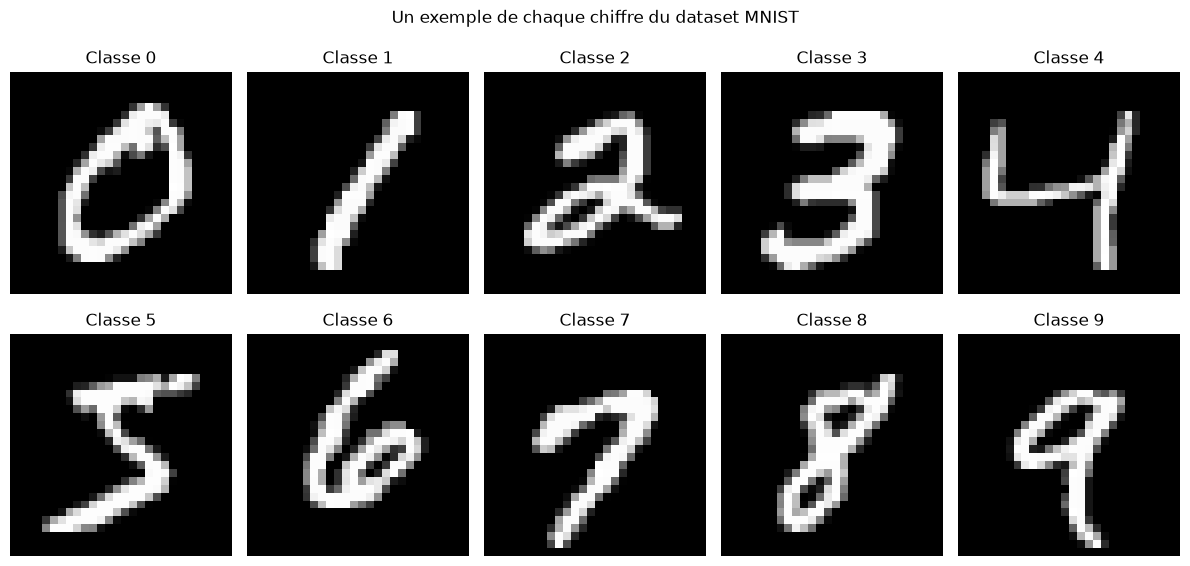

In [51]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for digit in range(10):
    idx = np.where(y_train_full == digit)[0][0]

    ax = axes[digit // 5, digit % 5]
    ax.imshow(x_train_full[idx], cmap="gray")
    ax.set_title(f"Classe {digit}")
    ax.axis("off")

plt.suptitle("Un exemple de chaque chiffre du dataset MNIST")
plt.tight_layout()
plt.savefig("../reports/figures/mnist_classes_examples.png", bbox_inches="tight")
plt.show()

# Analyse

Cette première visualisation montre que :

- les dix classes sont bien présentes ;
- les chiffres sont centrés dans l'image ;
- les écritures manuscrites présentent déjà une certaine variabilité ;
- certaines classes semblent plus ambiguës que d'autres (par exemple 4, 5 ou 9 selon l'écriture).

Ces observations justifient l'utilisation de modèles capables d'extraire automatiquement des caractéristiques visuelles pertinentes.

# Variabilité intra-classe

Nous observons plusieurs exemples de cahque chiffre afin d'évaluer la diversité des écritures manuscrites. 

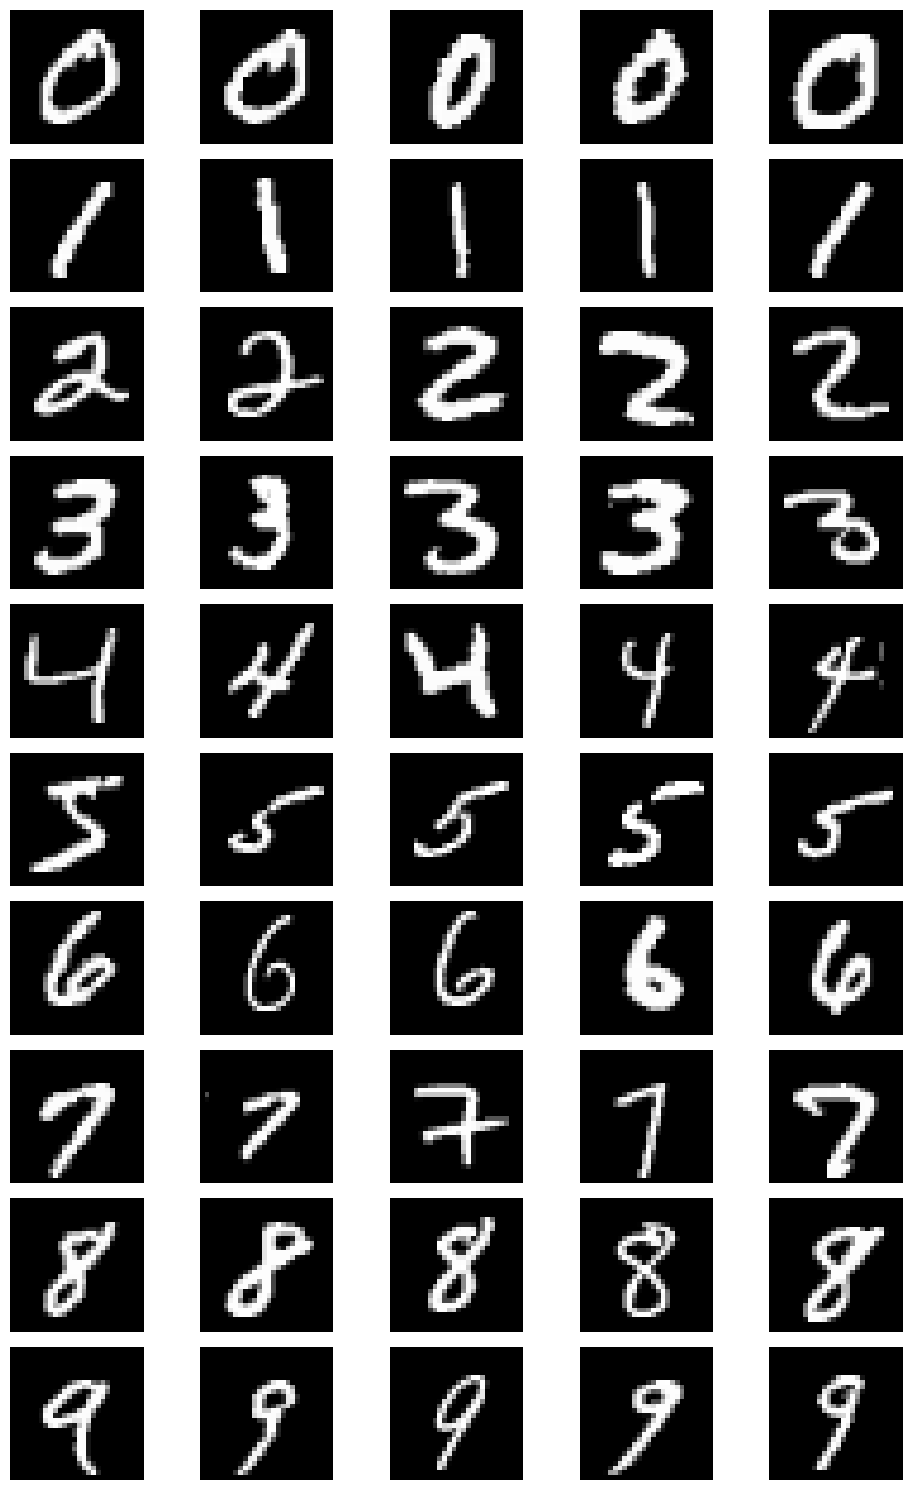

In [52]:
fig, axes = plt.subplots(10, 5, figsize=(10, 15))

for digit in range(10):
    indices = np.where(y_train_full == digit)[0][:5]

    for col, idx in enumerate(indices):
        axes[digit, col].imshow(x_train_full[idx], cmap="gray")

        if col == 0:
            axes[digit, col].set_ylabel(f"{digit}", rotation=0, labelpad=20)

        axes[digit, col].axis("off")

plt.tight_layout()
plt.savefig(
    "../reports/figures/mnist_classes_variability_examples.png", bbox_inches="tight"
)
plt.show()

# Analyse

L'affichage de plusieurs exemples par classe met en évidence une diversité visuelle des chiffres manuscrits.

On observe notamment :

- des épaisseurs de trait différentes ;
- des styles d'écriture variés selon les individus ;
- des légères variations d'inclinaison ;
- des différences de proportions et de centrage.

Cette observation reste qualitative puisqu'elle repose uniquement sur un sous-ensemble d'exemples du dataset.

Une étude quantitative de la variabilité nécessiterait des mesures statistiques ou des techniques de visualisation plus avancées.

# Conclusion DATA-02

Les dix classes du dataset ont été visualisées avec succès.

Les observations montrent :

- une bonne qualité générale des images ;
- une variabilité naturelle des écritures manuscrites ;
- la présence de formes parfois ambiguës pouvant conduire à certaines erreurs de classification.

L'étape suivante consiste à vérifier quantitativement la répartition des classes dans le dataset.

# Répartition des classes

Nous vérifions maintenant l'équilibre du dataset en comptabilisant le nombre d'occurrences de chaque chiffre.

In [53]:
class_counts = pd.Series(y_train_full).value_counts().sort_index()

class_counts

0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64

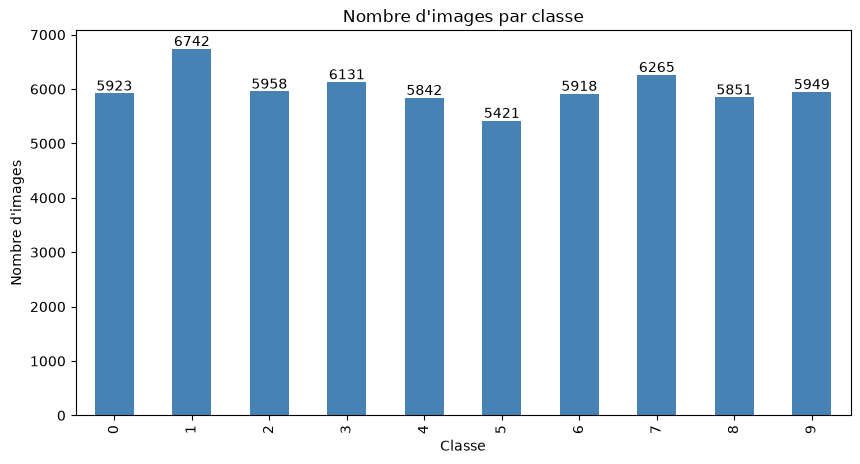

In [54]:
plt.figure(figsize=(10, 5))

ax = class_counts.plot(kind="bar", color="steelblue")

for i, value in enumerate(class_counts):
    ax.text(i, value + 50, str(value), ha="center")

plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
# sauvegarde de la figure
plt.savefig("../reports/figures/mnist_class_distribution.png", bbox_inches="tight")
plt.show()

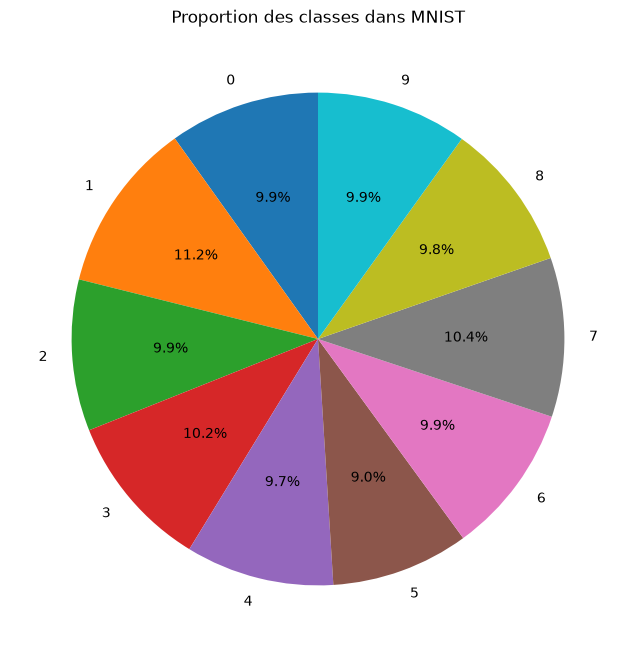

In [55]:
plt.figure(figsize=(8, 8))

plt.pie(class_counts, labels=class_counts.index, autopct="%1.1f%%", startangle=90)

plt.title("Proportion des classes dans MNIST")
# sauvegarde de la figure
plt.savefig("../reports/figures/mnist_class_distribution_pie.png", bbox_inches="tight")
plt.show()

In [56]:
print(
    f"Classe la moins représentée : {class_counts.idxmin()} "
    f"({class_counts.min()} images)"
)

print(
    f"Classe la plus représentée : {class_counts.idxmax()} "
    f"({class_counts.max()} images)"
)

Classe la moins représentée : 5 (5421 images)
Classe la plus représentée : 1 (6742 images)


# Analyse

La distribution des classes apparaît globalement équilibrée.

Le nombre d'images par classe varie entre :

- 5 421 images pour la classe 5 ;
- 6 742 images pour la classe 1.

L'écart maximal observé est donc de 1 321 images, soit environ 22 % de la taille de la classe la moins représentée.

Malgré ces variations, aucune classe ne semble fortement sous-représentée ou sur-représentée. Le dataset peut donc être considéré comme relativement équilibré.

Cette caractéristique est importante car elle limite les biais d'apprentissage qui pourraient apparaître si certaines classes étaient très peu représentées. Les performances futures des modèles pourront ainsi être comparées plus sereinement entre les différentes classes.

# Conclusion DATA-03

La répartition des classes a été vérifiée avec succès.

Observations principales :

- les dix classes sont présentes ;
- le dataset est globalement équilibré ;
- aucune classe n'apparaît fortement sous-représentée ;
- les conditions sont favorables à l'entraînement de modèles de classification.

L'étape suivante consiste à préparer les données en normalisant les valeurs des pixels avant l'entraînement des modèles.

Bien que certaines différences visuelles apparaissent entre les exemples d'une même classe, l'évaluation de cette variabilité reste ici qualitative. Une mesure quantitative plus avancée nécessiterait une analyse statistique des pixels ou des représentations apprises par les modèles.

# Variabilité intra-classe : image moyenne de chaque chiffre

Nous calculons l'image moyenne de chaque classe afin d'observer les formes les plus fréquemment rencontrées dans le dataset.

Les zones claires correspondent aux pixels activés de manière récurrente parmi les exemples d'une même classe.

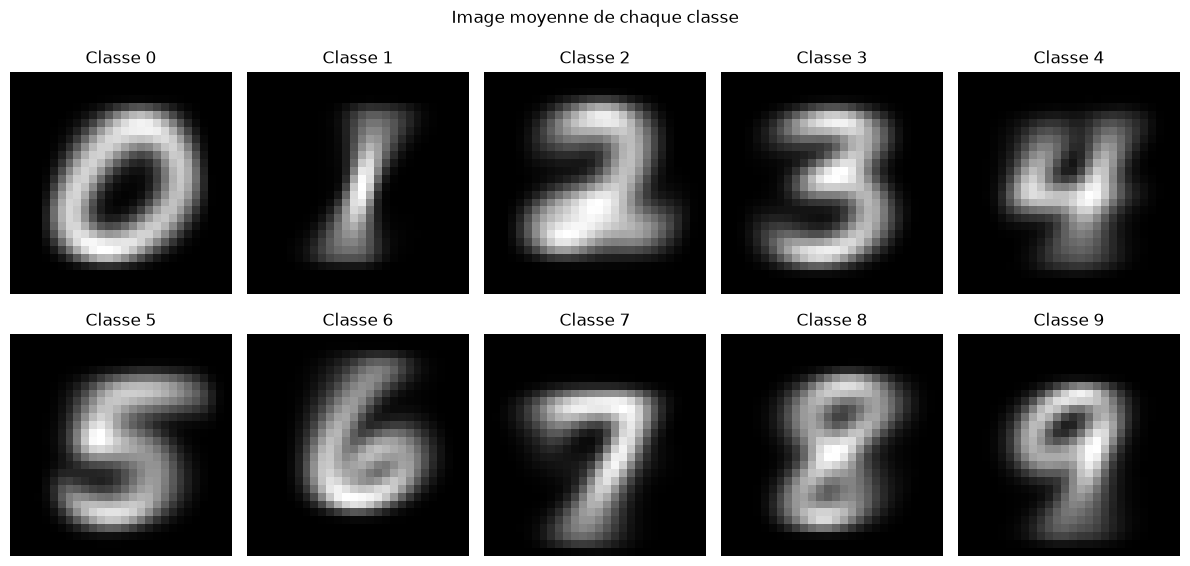

In [57]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for digit in range(10):
    mean_image = x_train_full[y_train_full == digit].mean(axis=0)

    ax = axes[digit // 5, digit % 5]
    ax.imshow(mean_image, cmap="gray")
    ax.set_title(f"Classe {digit}")
    ax.axis("off")

plt.suptitle("Image moyenne de chaque classe")
plt.tight_layout()
# sauvegarde de la figure
plt.savefig("../reports/figures/mnist_mean_images.png", bbox_inches="tight")
plt.show()

In [58]:
class_std = {}

for digit in range(10):
    std_value = x_train_full[y_train_full == digit].std()
    class_std[digit] = std_value

class_std

{0: np.float64(88.66807293975513),
 1: np.float64(62.29178755571119),
 2: np.float64(83.11048388578874),
 3: np.float64(81.0692353756164),
 4: np.float64(75.85848996400738),
 5: np.float64(77.41506624626122),
 6: np.float64(80.29885348978507),
 7: np.float64(74.38243138303984),
 8: np.float64(82.9412885831376),
 9: np.float64(76.15257205456176)}

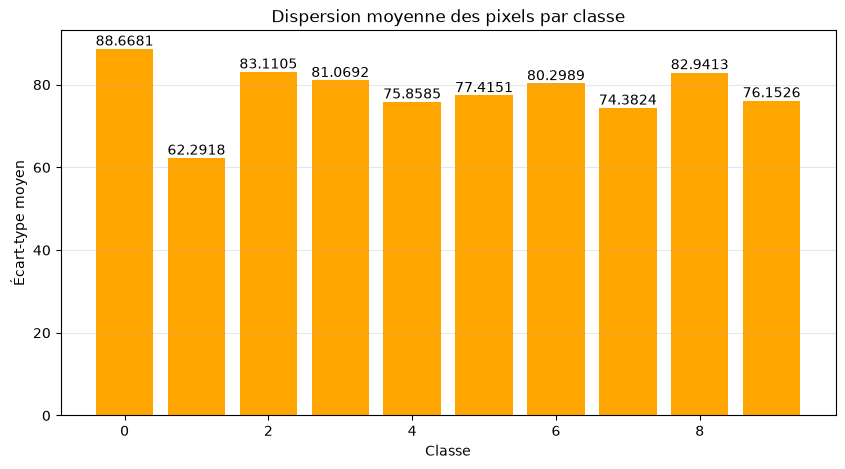

Classe la moins dispersée : 1 (écart-type moyen : 62.2918)
Classe la plus dispersée : 0 (écart-type moyen : 88.6681)
Classe 0 : écart-type moyen = 88.6681
Classe 1 : écart-type moyen = 62.2918
Classe 2 : écart-type moyen = 83.1105
Classe 3 : écart-type moyen = 81.0692
Classe 4 : écart-type moyen = 75.8585
Classe 5 : écart-type moyen = 77.4151
Classe 6 : écart-type moyen = 80.2989
Classe 7 : écart-type moyen = 74.3824
Classe 8 : écart-type moyen = 82.9413
Classe 9 : écart-type moyen = 76.1526


In [59]:
plt.figure(figsize=(10, 5))

bars = plt.bar(class_std.keys(), class_std.values(), color="orange")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
    )

plt.title("Dispersion moyenne des pixels par classe")
plt.xlabel("Classe")
plt.ylabel("Écart-type moyen")
plt.grid(axis="y", alpha=0.3)
# sauvegarde de la figure
plt.savefig("../reports/figures/mnist_class_dispersion.png", bbox_inches="tight")
plt.show()

print(
    f"Classe la moins dispersée : {min(class_std, key=class_std.get)} "
    f"(écart-type moyen : {min(class_std.values()):.4f})"
)

print(
    f"Classe la plus dispersée : {max(class_std, key=class_std.get)} "
    f"(écart-type moyen : {max(class_std.values()):.4f})"
)

# print les valeurs de dispersion pour chaque classe
for digit, std_value in class_std.items():
    print(f"Classe {digit} : écart-type moyen = {std_value:.4f}")

# Analyse de la variabilité intra-classe

Les images moyennes mettent en évidence les formes caractéristiques de chaque chiffre et permettent d'observer les zones les plus fréquemment activées.

L'analyse de la dispersion des pixels révèle des différences entre les classes.

La classe 1 présente la dispersion moyenne la plus faible avec un écart-type moyen de 62,29. Ce résultat est cohérent avec la simplicité géométrique du chiffre 1, généralement représenté par un trait vertical relativement similaire d'un individu à l'autre.

À l'inverse, la classe 0 présente la dispersion moyenne la plus élevée avec un écart-type moyen de 88,67. Cette plus forte variabilité peut s'expliquer par les différentes manières de tracer le chiffre (forme plus ou moins circulaire, ovale, étroite ou large).

Les classes 2, 3, 6 et 8 présentent également des dispersions élevées, suggérant une plus grande diversité dans les styles d'écriture observés.

Globalement, les résultats indiquent que certaines classes sont naturellement plus variables que d'autres. Cette variabilité constitue une difficulté supplémentaire pour les futurs modèles de classification qui devront être capables de reconnaître correctement ces différentes représentations d'un même chiffre.

# Conclusion de l'étude de variabilité

L'étude qualitative des exemples ainsi que l'analyse des dispersions montrent que toutes les classes ne présentent pas le même niveau de variabilité.

Les chiffres simples comme le 1 semblent relativement homogènes tandis que d'autres chiffres présentent des formes plus diverses.

Cette observation laisse supposer que certaines classes seront plus difficiles à classifier que d'autres. L'analyse des matrices de confusion réalisées ultérieurement permettra de vérifier cette hypothèse.

# Prétraitement et normalisation des données

Les valeurs des pixels de la base MNIST sont comprises entre 0 et 255.

Avant l'entraînement des modèles, il est recommandé de normaliser ces valeurs dans l'intervalle [0 ; 1] afin d'améliorer la stabilité numérique et de faciliter l'optimisation.

In [60]:
print("Avant normalisation")
print(f"Valeur minimale : {x_train_full.min()}")
print(f"Valeur maximale : {x_train_full.max()}")

Avant normalisation
Valeur minimale : 0
Valeur maximale : 255


In [61]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [62]:
print("Après normalisation")
print(f"Valeur minimale : {x_train_full.min()}")
print(f"Valeur maximale : {x_train_full.max()}")

Après normalisation
Valeur minimale : 0.0
Valeur maximale : 1.0


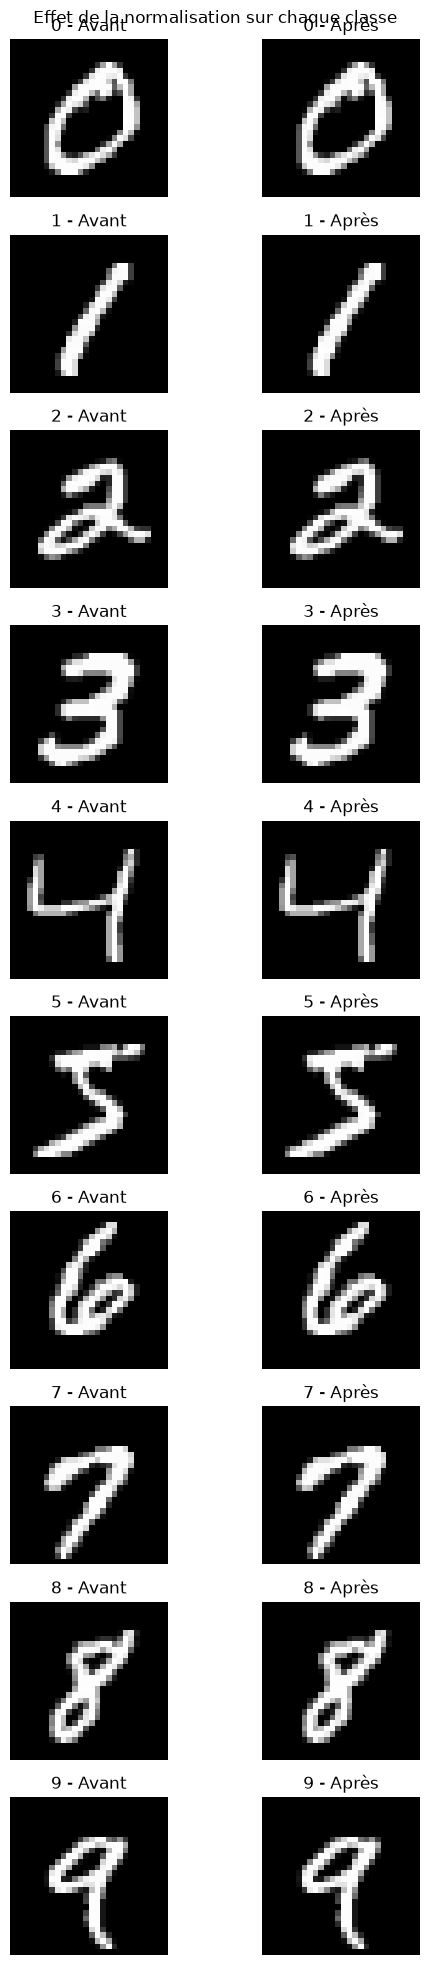

In [63]:
x_train_original = x_train_full.copy()
x_train_full = x_train_full.astype("float32") / 255.0
fig, axes = plt.subplots(10, 2, figsize=(6, 20))

for digit in range(10):
    idx = np.where(y_train_full == digit)[0][0]

    axes[digit, 0].imshow(x_train_original[idx], cmap="gray")
    axes[digit, 0].set_title(f"{digit} - Avant")
    axes[digit, 0].axis("off")

    axes[digit, 1].imshow(x_train_full[idx], cmap="gray")
    axes[digit, 1].set_title(f"{digit} - Après")
    axes[digit, 1].axis("off")

plt.suptitle("Effet de la normalisation sur chaque classe")
plt.savefig("../reports/figures/mnist_normalization_effect.png", bbox_inches="tight")
plt.tight_layout()
plt.show()

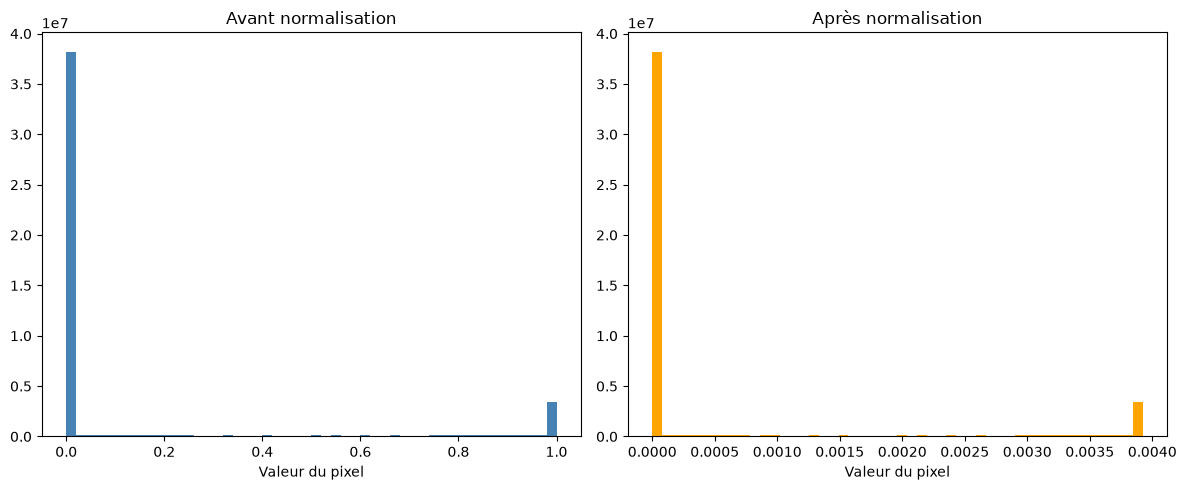

Avant normalisation
Valeur minimale : 0.0
Valeur maximale : 1.0
Après normalisation
Valeur minimale : 0.0
Valeur maximale : 0.003921568859368563


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(x_train_original.flatten(), bins=50, color="steelblue")

axes[0].set_title("Avant normalisation")

axes[0].set_xlabel("Valeur du pixel")

axes[1].hist(x_train_full.flatten(), bins=50, color="orange")

axes[1].set_title("Après normalisation")

axes[1].set_xlabel("Valeur du pixel")

plt.tight_layout()
plt.show()

print("Avant normalisation")
print(f"Valeur minimale : {x_train_original.min()}")
print(f"Valeur maximale : {x_train_original.max()}")

print("Après normalisation")
print(f"Valeur minimale : {x_train_full.min()}")
print(f"Valeur maximale : {x_train_full.max()}")

# Analyse

La normalisation a correctement transformé les valeurs des pixels de l'intervalle [0 ; 255] vers l'intervalle [0 ; 1].

Cette transformation ne modifie pas le contenu visuel des images mais change leur échelle numérique.

Cette étape est particulièrement importante pour les modèles de Deep Learning car elle facilite généralement la convergence lors de l'entraînement.

# Conclusion DATA-04

Les images ont été normalisées avec succès.

Les valeurs des pixels sont désormais comprises entre 0 et 1, ce qui constitue le format utilisé pour les futurs modèles de classification.